In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv("food_delivery_orders.csv")
df.head(5)

,order_date,city,restaurant_category,cuisine,order_value,discount_percent,delivery_time_min,rating,profit_per_order
0,2023-01-01,Karachi,Fine Dining,Continental,2768.0,25.0,36.2,4.5,95.0
1,2023-01-01,Karachi,Fine Dining,Steakhouse,4979.0,44.8,23.3,4.8,-437.0
2,2023-01-01,Karachi,Cloud Kitchen,Indian,4008.0,11.9,39.6,4.2,618.0
3,2023-01-01,Islamabad,Fine Dining,Steakhouse,3260.0,8.3,35.8,4.5,423.0
4,2023-01-01,Karachi,Fast Food,Pizza,435.0,13.5,29.4,4.8,53.0


Mean: 34.541809523809526
Median: 32.5


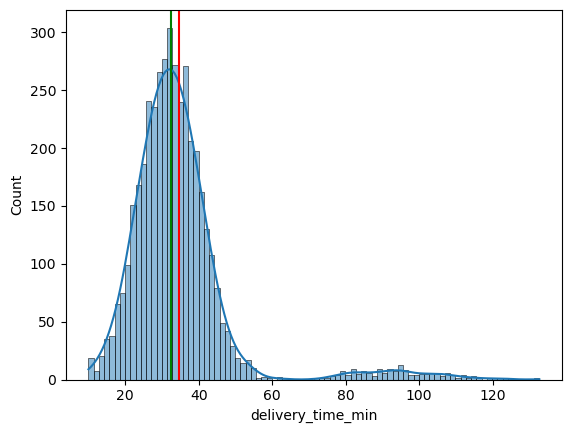

In [17]:
#task 1

mean = df["delivery_time_min"].mean()
median = df["delivery_time_min"].median()
col = df["delivery_time_min"]

sns.histplot(col, kde = 'true')
plt.axvline(mean, color='red', label='Mean')
plt.axvline(median, color='green', label='Median')
print("Mean:", mean)
print("Median:", median)


#Median should be used as it better represents typical delivery time as mean is shifted to the right due to right skewness of the data

<Axes: xlabel='city', ylabel='rating'>

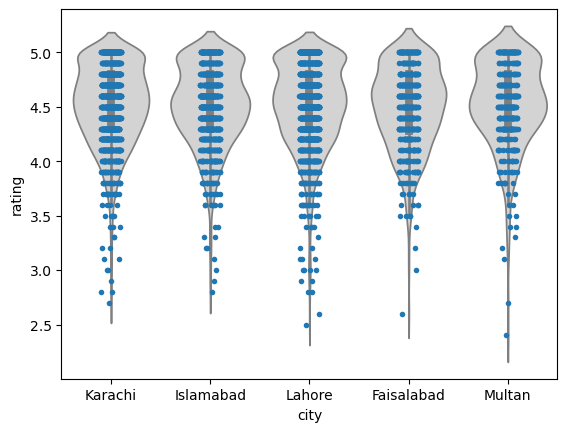

In [30]:
#task 2


sns.violinplot(data=df, x='city', y='rating', color='lightgray')
sns.stripplot(data=df, x='city', y='rating', jitter=True,  size=4)

#Islamabad has the most inconsistent as it has bimodal pattern and is more spread compared to the rest.
#There is a lot of ratings for 5 then less for the rest then a lot again for 4.5 

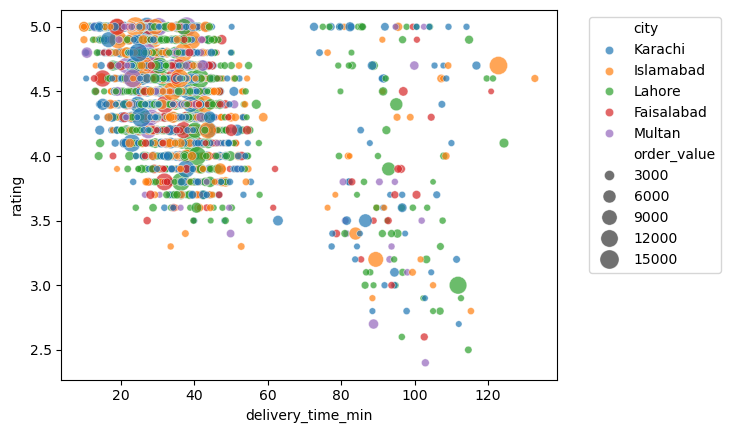

In [35]:
#task 3

sns.scatterplot(data=df, x='delivery_time_min', y='rating', hue='city', size='order_value', sizes=(20, 200), alpha=0.7)

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


#a huge cluster of high rated orders are concentrated where delivery time is very low
#but we can also see with order_value that higher order value get less delivery times and hence more rating 
#as there are larger area circles in that cluster while outside that are almost all small dots

largest difference: ('order_value', 'profit_per_order')
Pearson: -0.6571444205999941
Spearman:  0.673114122160055


Text(0.5, 1.0, 'Spearman Correlation')

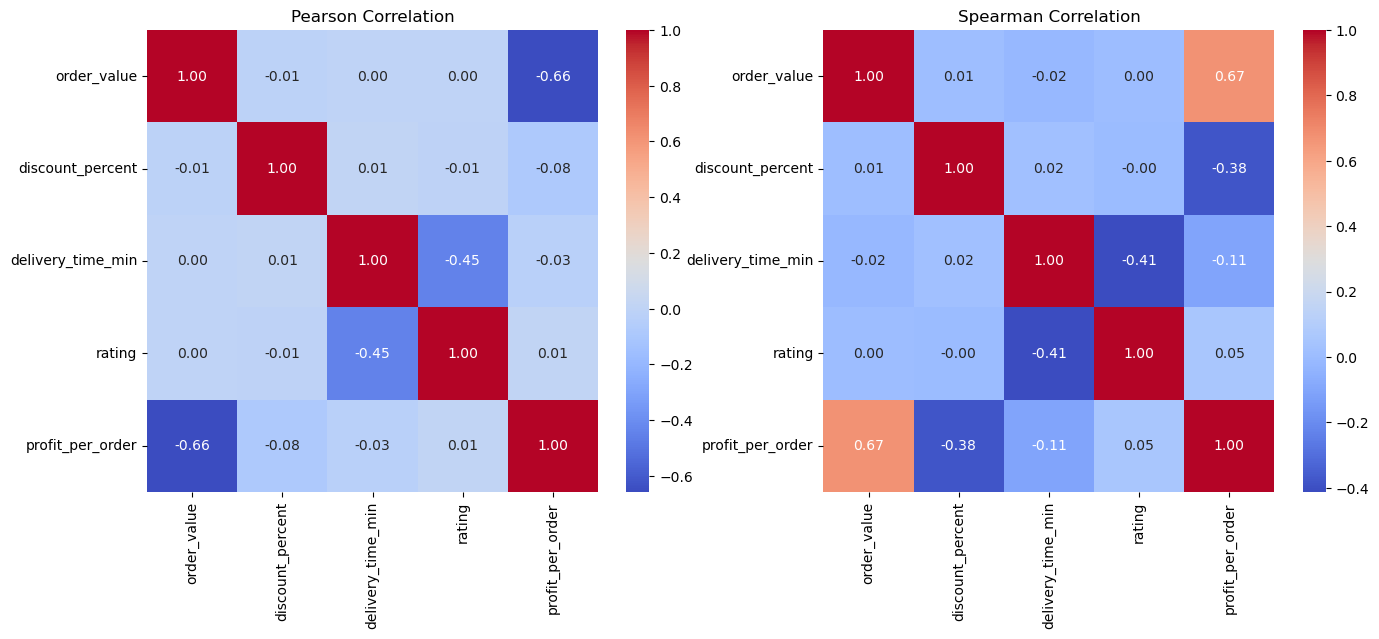

In [42]:
#task 4

num_cols = ['order_value', 'discount_percent', 'delivery_time_min', 'rating', 'profit_per_order']
pearson = df[num_cols].corr(method='pearson')
spearman = df[num_cols].corr(method='spearman')

diff = (pearson - spearman).abs()
for col in diff.columns:
    diff.loc[col, col] = 0

max_diff_idx = diff.unstack().idxmax()
print("largest difference:", max_diff_idx)
print("Pearson:", pearson.loc[max_diff_idx])
print("Spearman: ", spearman.loc[max_diff_idx])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df[num_cols].corr(method='pearson'), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[0])
axes[0].set_title('Pearson Correlation')

sns.heatmap(df[num_cols].corr(method='spearman'), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[1])
axes[1].set_title('Spearman Correlation')

#they have the largest difference in order_value and profit_per_order due to some outliers in the dataset
#they should not be dropped as they still are real data but they might not have direct causation between each other

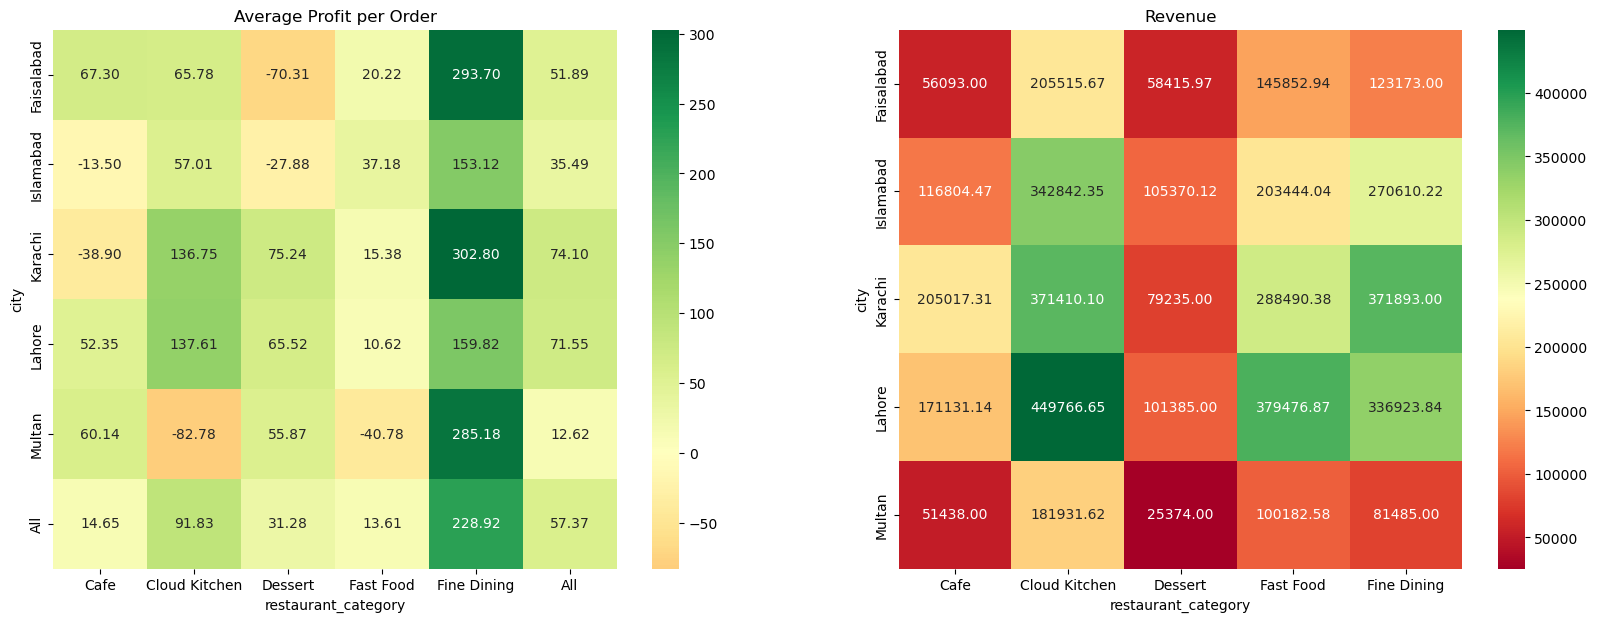

In [78]:
#task 5

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

pivot_table = df.pivot_table(index='city', columns='restaurant_category', values='profit_per_order', aggfunc='mean', margins=True)
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap='RdYlGn',center=0, ax=axes[0])
axes[0].set_title('Average Profit per Order')



revenue_pivot = df.pivot_table(index='city', columns='restaurant_category', values='order_value', aggfunc='sum')
sns.heatmap(revenue_pivot, annot=True, fmt=".2f", cmap='RdYlGn', ax=axes[1])
axes[1].set_title('Revenue')
plt.show()

#highest combination is Karachi with Fine dining, but karachi with fine dining is not the highest revenue generator 

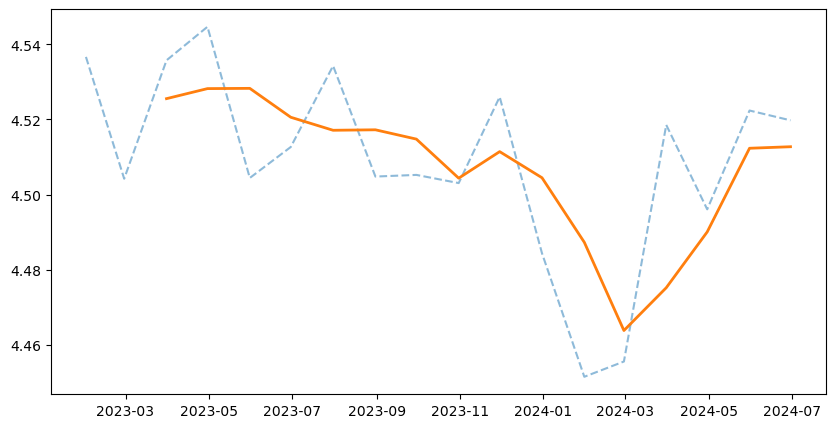

In [65]:
#task 6

monthly_rating = df['rating'].resample('ME').mean()
rolling_rating = monthly_rating.rolling(window=3).mean()


plt.figure(figsize=(10, 5))
plt.plot(monthly_rating.index, monthly_rating, label='Raw Monthly Average', alpha=0.5, linestyle='--')
plt.plot(rolling_rating.index, rolling_rating, label='3-Month Rolling Average', linewidth=2)
#dotted line is the average rating per month the solid line is the rolling average 
#the dotted shows huge dips and noise between months but the solid line smoothes them out well 
#I would've said there is huge variance in the raw monthly line but the solid line shows the actual smoothed out rating average

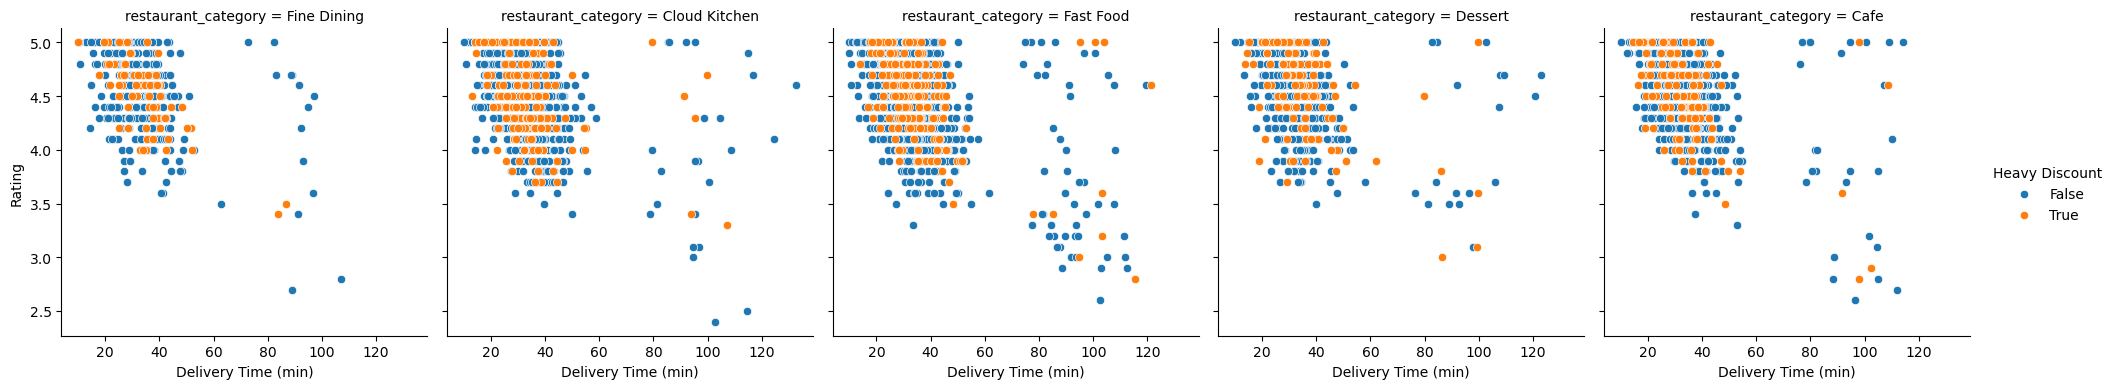

In [76]:
#task 7

df["heavy_discount"] = df["discount_percent"] > 20

g = sns.FacetGrid(df, col="restaurant_category", hue="heavy_discount", height=4, aspect=1)
g.map_dataframe(sns.scatterplot, x="delivery_time_min", y="rating")
g.set_axis_labels("Delivery Time (min)", "Rating")
g.add_legend(title="Heavy Discount")
plt.show()

#in fast food they are more forgiving with late delivery if they are given heavy discount
#as there are like 3 points with 5 star that have 100+ min time but 5 stars

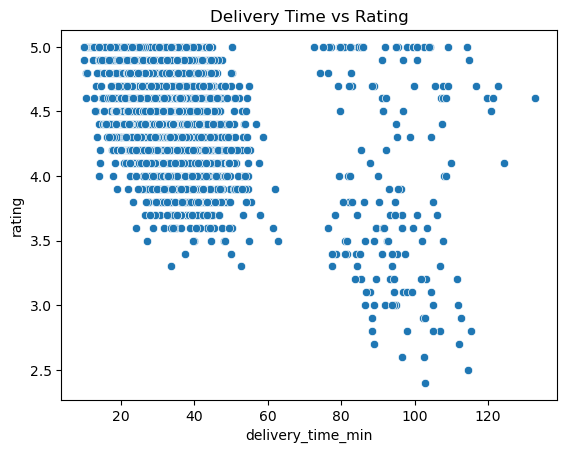

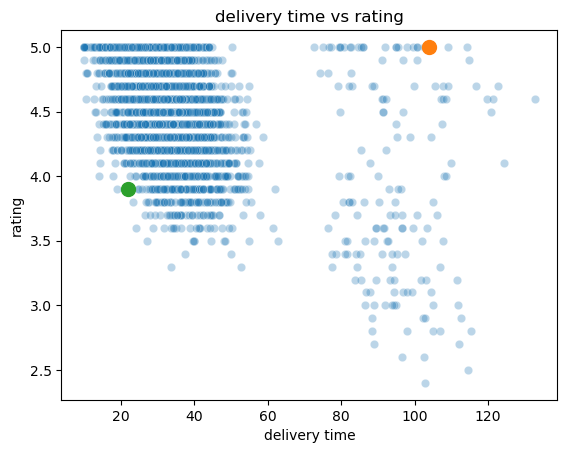

In [80]:
sns.scatterplot(data=df, x="delivery_time_min", y="rating")
plt.title("Delivery Time vs Rating")
plt.show()

long = df[df["delivery_time_min"] >= df["delivery_time_min"].quantile(0.9)]
fast = df[df["delivery_time_min"] <= df["delivery_time_min"].quantile(0.1)]

best_long = long.sort_values("rating", ascending=False).iloc[0]
worst_fast = fast.sort_values("rating").iloc[0]
sns.scatterplot(data=df, x="delivery_time_min", y="rating", alpha=0.3)
plt.scatter(best_long["delivery_time_min"], best_long["rating"], s=100)
plt.scatter(worst_fast["delivery_time_min"], worst_fast["rating"], s=100)

plt.title("delivery time vs rating")
plt.xlabel("delivery time")
plt.ylabel("rating")
plt.show()

#alpha transparency makes it easy to see plots properly especially when there is overplotting and overalpping between them
#green is low delivery time and low rating and orange is high rating with high delivery time